2025-05-30 13:41:21.650053: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:477] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1748612481.912245      35 cuda_dnn.cc:8310] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1748612481.982032      35 cuda_blas.cc:1418] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered


Found 8863 images belonging to 2 classes.
Found 600 images belonging to 2 classes.


I0000 00:00:1748612499.672725      35 gpu_device.cc:2022] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 15513 MB memory:  -> device: 0, name: Tesla P100-PCIE-16GB, pci bus id: 0000:00:04.0, compute capability: 6.0


58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step


/usr/local/lib/python3.11/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/15


I0000 00:00:1748612507.868043     108 service.cc:148] XLA service 0x78a0e0011040 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1748612507.869076     108 service.cc:156]   StreamExecutor device (0): Tesla P100-PCIE-16GB, Compute Capability 6.0
I0000 00:00:1748612508.354345     108 cuda_dnn.cc:529] Loaded cuDNN version 90300


  2/277 ━━━━━━━━━━━━━━━━━━━━ 25s 94ms/step - accuracy: 0.8359 - loss: 0.3842   

I0000 00:00:1748612517.774305     108 device_compiler.h:188] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


277/277 ━━━━━━━━━━━━━━━━━━━━ 142s 467ms/step - accuracy: 0.4990 - loss: 0.8577
Epoch 2/15
277/277 ━━━━━━━━━━━━━━━━━━━━ 101s 362ms/step - accuracy: 0.5956 - loss: 0.7013
Epoch 3/15
277/277 ━━━━━━━━━━━━━━━━━━━━ 100s 360ms/step - accuracy: 0.6626 - loss: 0.6094
Epoch 4/15
277/277 ━━━━━━━━━━━━━━━━━━━━ 100s 362ms/step - accuracy: 0.7883 - loss: 0.4629
Epoch 5/15
277/277 ━━━━━━━━━━━━━━━━━━━━ 101s 363ms/step - accuracy: 0.7977 - loss: 0.4206
Epoch 6/15
277/277 ━━━━━━━━━━━━━━━━━━━━ 99s 358ms/step - accuracy: 0.8399 - loss: 0.3451
Epoch 7/15
277/277 ━━━━━━━━━━━━━━━━━━━━ 99s 357ms/step - accuracy: 0.8614 - loss: 0.3161
Epoch 8/15
277/277 ━━━━━━━━━━━━━━━━━━━━ 100s 361ms/step - accuracy: 0.9037 - loss: 0.2316
Epoch 9/15
277/277 ━━━━━━━━━━━━━━━━━━━━ 102s 368ms/step - accuracy: 0.9162 - loss: 0.2067
Epoch 10/15
277/277 ━━━━━━━━━━━━━━━━━━━━ 98s 354ms/step - accuracy: 0.9404 - loss: 0.1460
Epoch 11/15
277/277 ━━━━━━━━━━━━━━━━━━━━ 100s 359ms/step - accuracy: 0.9362 - loss: 0.1606
Epoch 12/15
277/277 ━━

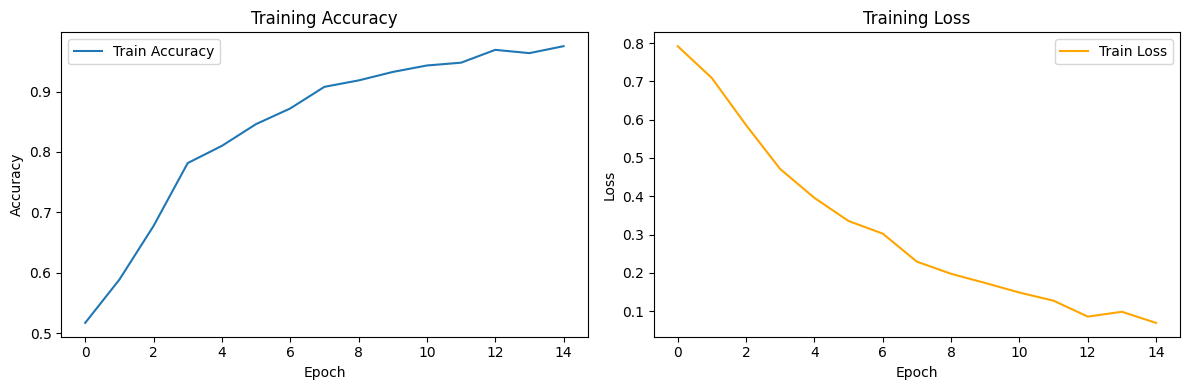

277/277 ━━━━━━━━━━━━━━━━━━━━ 99s 355ms/step

[TRAINING CLASSIFICATION REPORT]

               precision    recall  f1-score   support

    fractured       1.00      0.95      0.97      4480
not_fractured       0.95      1.00      0.97      4383

     accuracy                           0.97      8863
    macro avg       0.97      0.97      0.97      8863
 weighted avg       0.97      0.97      0.97      8863



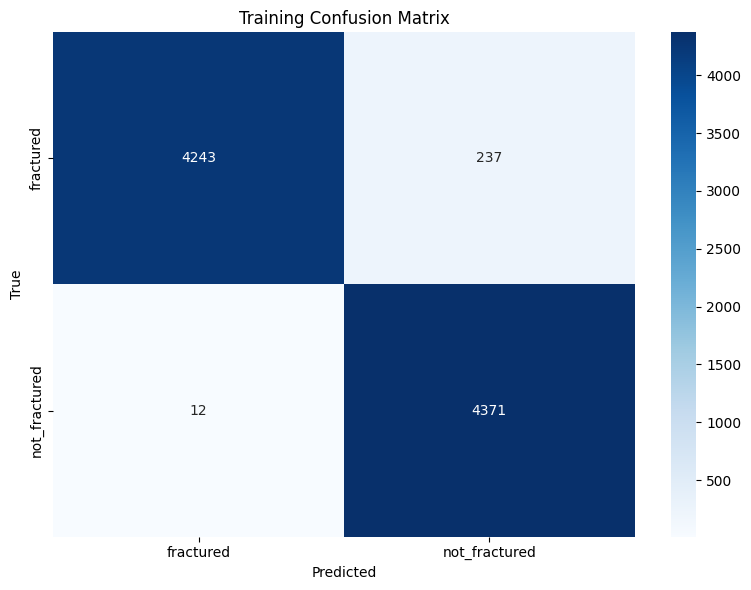

/usr/local/lib/python3.11/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


19/19 ━━━━━━━━━━━━━━━━━━━━ 9s 480ms/step

[TESTING CLASSIFICATION REPORT]

               precision    recall  f1-score   support

    fractured       0.95      0.41      0.57       360
not_fractured       0.52      0.97      0.68       240

     accuracy                           0.63       600
    macro avg       0.73      0.69      0.62       600
 weighted avg       0.78      0.63      0.61       600



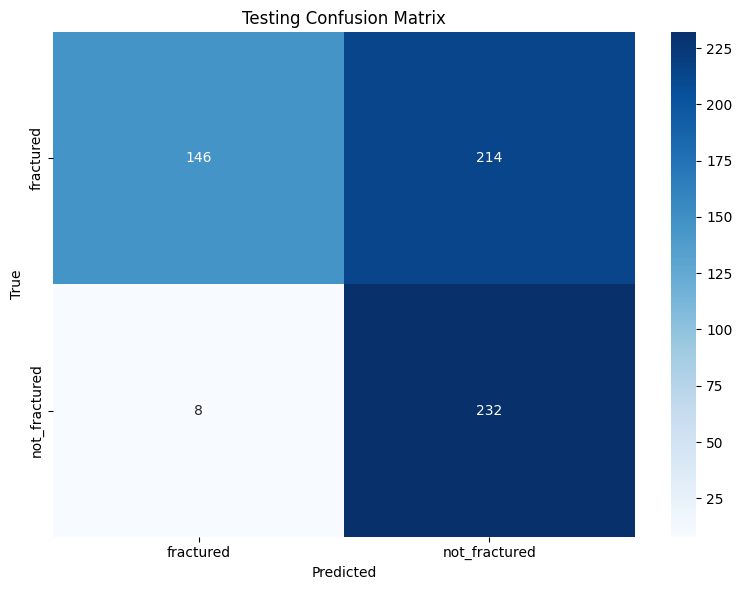

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications import VGG16
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Dense, Flatten, Dropout
from tensorflow.keras.optimizers import Adam
from sklearn.metrics import classification_report, confusion_matrix

# --- SETUP ---
train_dir = '/kaggle/input/x-ray-dection/Bone Fracture Dataset/training'
test_dir = '/kaggle/input/x-ray-dection/Bone Fracture Dataset/testing'

# --- BOOSTED DATA AUGMENTATION ---
train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=30,
    width_shift_range=0.1,
    height_shift_range=0.1,
    zoom_range=0.3,
    shear_range=0.3,
    horizontal_flip=True,
    fill_mode='nearest'
)
test_datagen = ImageDataGenerator(rescale=1./255)

train_generator = train_datagen.flow_from_directory(
    train_dir, target_size=(224, 224), batch_size=32, class_mode='categorical', shuffle=False
)
test_generator = test_datagen.flow_from_directory(
    test_dir, target_size=(224, 224), batch_size=32, class_mode='categorical', shuffle=False
)

# --- MODEL DEFINITION ---
base_model = VGG16(weights='imagenet', include_top=False, input_shape=(224, 224, 3))

# Fine-tune the top 4 layers
for layer in base_model.layers[:-4]:
    layer.trainable = False
for layer in base_model.layers[-4:]:
    layer.trainable = True

x = Flatten()(base_model.output)
x = Dense(512, activation='relu')(x)
x = Dropout(0.5)(x)
output = Dense(train_generator.num_classes, activation='softmax')(x)

model = Model(inputs=base_model.input, outputs=output)
model.compile(optimizer=Adam(learning_rate=1e-5), loss='categorical_crossentropy', metrics=['accuracy'])

# --- TRAINING ---
history = model.fit(train_generator, epochs=15)

# --- PLOT: Accuracy and Loss ---
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.title('Training Accuracy')
plt.xlabel('Epoch'); plt.ylabel('Accuracy'); plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Train Loss', color='orange')
plt.title('Training Loss')
plt.xlabel('Epoch'); plt.ylabel('Loss'); plt.legend()

plt.tight_layout()
plt.show()

# --- EVALUATION FUNCTION ---
def evaluate_and_report(generator, preds, dataset_name, class_labels, file_prefix):
    y_pred = np.argmax(preds, axis=1)
    y_true = generator.classes

    # Classification Report
    print(f"\n[{dataset_name.upper()} CLASSIFICATION REPORT]\n")
    print(classification_report(y_true, y_pred, target_names=class_labels))

    # Confusion Matrix
    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(8, 6))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=class_labels, yticklabels=class_labels)
    plt.title(f'{dataset_name} Confusion Matrix')
    plt.xlabel('Predicted'); plt.ylabel('True')
    plt.tight_layout()
    plt.savefig(f'{file_prefix}_confusion_matrix.png')
    plt.show()

# --- TRAINING EVALUATION ---
train_preds = model.predict(train_generator, verbose=1)
class_labels = list(train_generator.class_indices.keys())
evaluate_and_report(train_generator, train_preds, 'Training', class_labels, 'training')

# --- TESTING EVALUATION ---
test_preds = model.predict(test_generator, verbose=1)
evaluate_and_report(test_generator, test_preds, 'Testing', class_labels, 'testing')
